# Подбор порога классификации под цену ошибки (Telco Customer Churn)

**Задача:** предсказать, уйдёт ли клиент телеком-оператора (`Churn = Yes`). Положительный класс (1) — клиент уходит.

**Датасет:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), 7043 клиента, 19 признаков после удаления `customerID` и целевой переменной.

**Цена ошибок (по заданию):** _____.
Принято соотношение стоимостей **FN : FP = 5 : 1**: пропуск уходящего клиента (FN) в 5 раз дороже лишнего предложения остающемуся клиенту (FP).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
)

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Дисбаланс классов

Доля клиентов, которые остались: 73.5%, ушли: 26.5%. Классы несбалансированы, поэтому одной accuracy оценивать модель нельзя: константная модель «все остаются» уже получила бы accuracy ≈ 0.735, не найдя ни одного уходящего клиента. Поэтому дальше используются precision, recall, F1, ROC/PR-кривые и суммарная стоимость ошибок.

Столбец `TotalCharges` загружался как строка (у 11 новых клиентов в нём пробел), он приведён к числу, пропуски (11 шт.) заполняются медианой внутри пайплайна. `SeniorCitizen` (0/1) трактуется как категория.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Пропусков TotalCharges:", df["TotalCharges"].isna().sum())

y = (df["Churn"] == "Yes").astype(int)          # 1 = клиент уходит (положительный класс)
X = df.drop(columns=["Churn", "customerID"])
X["SeniorCitizen"] = X["SeniorCitizen"].astype(str)   # 0/1 по смыслу категория

num_features = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_features = [c for c in X.columns if c not in num_features]
print(len(num_features), "числовых,", len(cat_features), "категориальных")

Пропусков TotalCharges: 11
3 числовых, 16 категориальных


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [6]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_features),
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LogisticRegression(max_iter=1000)),
])

In [7]:
model.fit(X_train, y_train)
proba_test = model.predict_proba(X_test)[:, 1]    # вероятность класса 1 (уйдёт)
print(proba_test[:10].round(3))

[0.045 0.684 0.059 0.401 0.022 0.603 0.448 0.131 0.003 0.395]


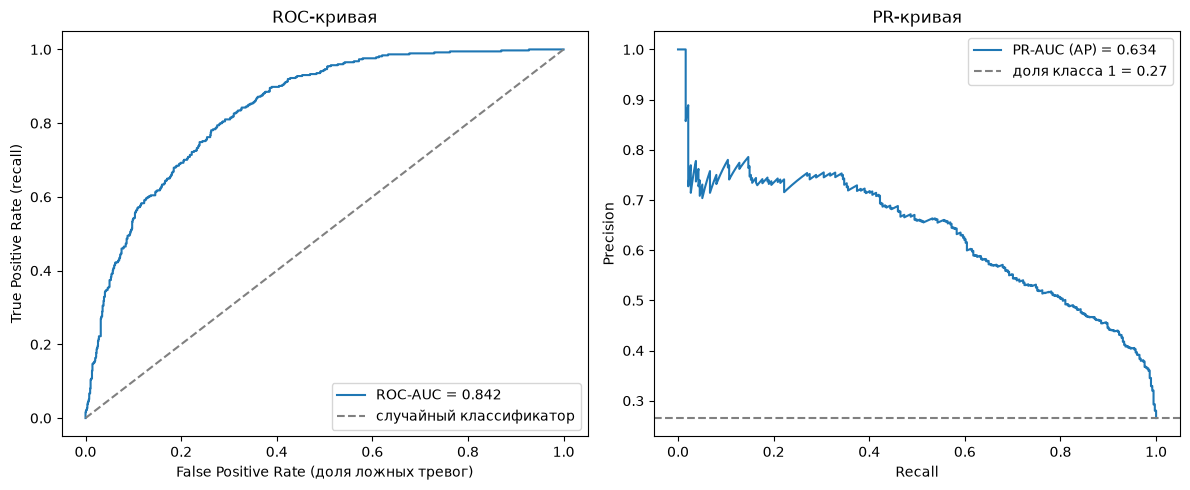

In [8]:
roc_auc = roc_auc_score(y_test, proba_test)
ap = average_precision_score(y_test, proba_test)
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="случайный классификатор")
ax[0].set_xlabel("False Positive Rate (доля ложных тревог)")
ax[0].set_ylabel("True Positive Rate (recall)")
ax[0].set_title("ROC-кривая")
ax[0].legend()

ax[1].plot(rec, prec, label=f"PR-AUC (AP) = {ap:.3f}")
ax[1].axhline(y_test.mean(), ls="--", color="gray", label=f"доля класса 1 = {y_test.mean():.2f}")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("PR-кривая")
ax[1].legend()

plt.tight_layout()
plt.show()

## Интерпретация ROC-AUC и PR-AUC

**ROC-AUC = 0.842.** Это вероятность того, что случайно выбранный уходящий клиент получит от модели более высокую вероятность ухода, чем случайно выбранный остающийся. Значение 0.5 означало бы угадывание, 1.0 — идеальное разделение. 0.842 — хорошее качество ранжирования клиентов по риску ухода. Метрика не зависит от порога.

**PR-AUC (Average Precision) = 0.634.** Базовый уровень случайной модели равен доле положительного класса (≈ 0.27), то есть модель работает примерно в 2.4 раза лучше случайной. При дисбалансе PR-кривая информативнее ROC: ROC-AUC может выглядеть оптимистично из-за большого числа истинно отрицательных.

По PR-кривой видно, что precision падает с ростом recall: чтобы найти больше уходящих клиентов, придётся принять больше ложных тревог. Именно этот компромисс регулируется порогом.

AUC оценивает только ранжирование и не говорит, какой порог выбрать. Для этого нужна цена ошибок.

In [9]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

print(evaluate(y_test, proba_test, 0.5))

{'threshold': 0.5, 'accuracy': 0.8055358410220014, 'precision': 0.6572327044025157, 'recall': 0.5588235294117647, 'f1': 0.6040462427745664, 'TN': np.int64(926), 'FP': np.int64(109), 'FN': np.int64(165), 'TP': np.int64(209)}


Лучший порог: 0.16


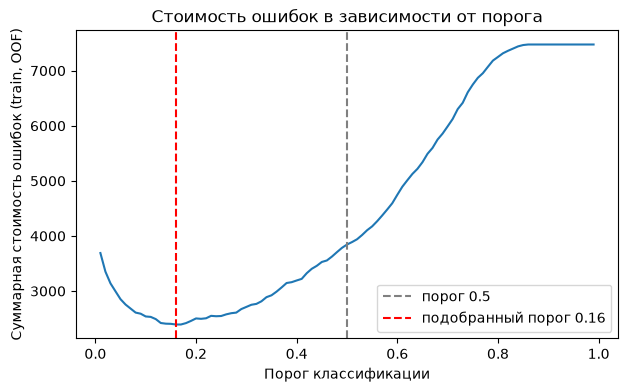

In [ ]:
COST_FN = 5  
COST_FP = 1  

# вероятности на train, полученные кросс-валидацией: модель не видела предсказываемые строки
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.01, 0.99, 99)
costs = []
for t in thresholds:
    pred = (proba_oof >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    costs.append(COST_FN * fn + COST_FP * fp)

best_t = thresholds[int(np.argmin(costs))]
print("Лучший порог:", round(best_t, 2))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs)
plt.axvline(0.5, ls="--", color="gray", label="порог 0.5")
plt.axvline(best_t, ls="--", color="red", label=f"подобранный порог {best_t:.2f}")
plt.xlabel("Порог классификации")
plt.ylabel("Суммарная стоимость ошибок (train, OOF)")
plt.title("Стоимость ошибок в зависимости от порога")
plt.legend()
plt.show()

## Выбор порога

**Почему не 0.5.** Порог 0.5 неявно считает FP и FN одинаково дорогими. По условию задачи это не так: пропущенный уходящий клиент обходится в 5 раз дороже, чем лишнее предложение.

**Как подобран.** Перебраны пороги от 0.01 до 0.99, для каждого посчитана суммарная стоимость `5·FN + 1·FP`. Вероятности получены через `cross_val_predict` (5 фолдов) **на обучающей выборке**: каждая строка предсказана моделью, которая её не видела. Тестовая выборка при подборе не использовалась, поэтому утечки нет. Минимум стоимости достигнут при пороге **0.16**.

**Проверка теорией.** Для откалиброванных вероятностей оптимальный порог равен C_FP / (C_FP + C_FN) = 1 / (1 + 5) ≈ 0.167. Полученные 0.16 практически совпадают с ним, что подтверждает выбор.

In [11]:
res = pd.DataFrame([
    evaluate(y_test, proba_test, 0.5),
    evaluate(y_test, proba_test, best_t),
], index=["порог 0.5", f"порог {best_t:.2f}"])

res["стоимость ошибок"] = COST_FN * res["FN"] + COST_FP * res["FP"]
res.round(3)

,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP,стоимость ошибок
порог 0.5,0.50,0.806,0.657,0.559,0.604,926,109,165,209,934
порог 0.16,0.16,0.674,0.443,0.901,0.594,612,423,37,337,608


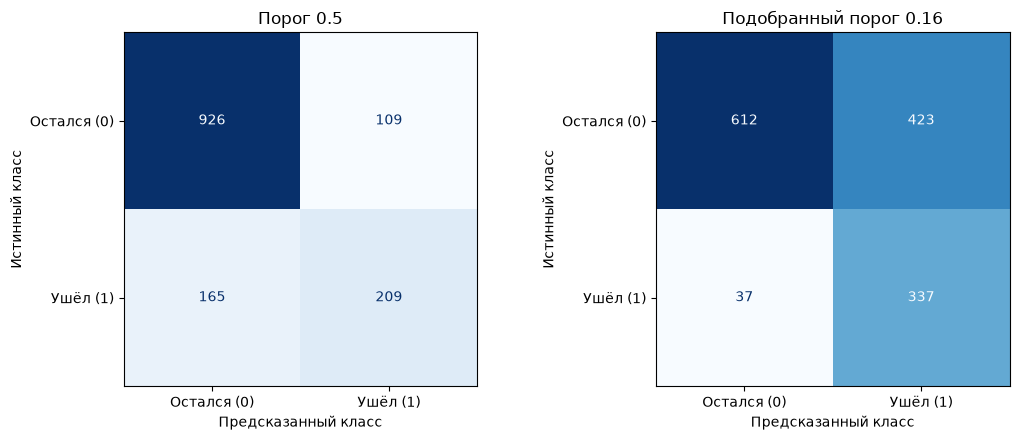

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t, title in zip(axes, [0.5, best_t], ["Порог 0.5", f"Подобранный порог {best_t:.2f}"]):
    pred = (proba_test >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Остался (0)", "Ушёл (1)"],
        cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
plt.tight_layout()
plt.show()

## Сравнение порогов на test

| | threshold | accuracy | precision | recall | F1 | FN | FP | стоимость |
|---|---|---|---|---|---|---|---|---|
| порог 0.5 | 0.50 | 0.806 | 0.657 | 0.559 | 0.604 | 165 | 109 | 934 |
| порог 0.16 | 0.16 | 0.674 | 0.443 | 0.901 | 0.594 | 37 | 423 | 608 |

## Вывод

При снижении порога с 0.5 до 0.16 recall вырос с 0.559 до 0.901: модель находит 337 из 374 уходящих клиентов вместо 209, а пропущенных (FN) стало 37 вместо 165. Платой стал рост ложных тревог (FP) со 109 до 423 и падение precision с 0.657 до 0.443: теперь менее половины предложений уходят «по адресу». Accuracy снизилась с 0.806 до 0.674, а F1 почти не изменился (0.604 и 0.594).

С учётом цены ошибок (FN в 5 раз дороже FP) суммарная стоимость на test снизилась с **934 до 608**, то есть примерно на 35%. Дополнительно найденные 128 клиентов «сэкономили» 128·5 = 640 единиц, а 314 лишних ложных тревог стоили 314, итого выигрыш 326.

Падение accuracy — осознанный компромисс, а не ухудшение модели. Показательно, что accuracy при пороге 0.16 (0.674) даже ниже, чем у константной модели «никто не уходит» (≈ 0.735), но такая модель бесполезна для бизнеса: её recall равен нулю. Это иллюстрирует, почему при дисбаланса классов и неравной цене ошибок accuracy нельзя использовать как основную метрику.

**Ограничение.** Выбранный порог зависит от принятого соотношения 5 : 1. Если реальная цена ошибок другая, порог нужно пересчитать (код это делает автоматически изменением `COST_FN` и `COST_FP`).